# `rioxarray`

In this lesson we will introduce [`rioxarray`](https://corteva.github.io/rioxarray/stable/), a Python extension for `xarray` to manipulate `xarray.DataArray`s as rasters. 

The name `rioxarray` stands for *raster input/output + xarray*. 

## About the data
The raster files we will use today come from the [US National Agriculture Imagery Program (NAIP)](https://naip-usdaonline.hub.arcgis.com). 
NAIP images are are high-resolution aerial images with four spectral bands: red (R), green (G), blue (B) and near-infrared (NIR). 
The raster's we'll use today are from 2020.

The data used in this lesson was pre-processing from a complete NAIP scene to separate the RGB bands from the NIR band and reduce the spatial extent. 
The data was accessed through [Microsoft's Planetary Computer NAIP data repository](https://planetarycomputer.microsoft.com/dataset/naip#overview).

## Import a TIF file

Let's start by loading the libraries we will use: 

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import rioxarray as rioxr

There are [multiple ways of opening a TIF file using `xarray` or `rioxarray`](https://corteva.github.io/rioxarray/html/getting_started/getting_started.html). 
Using the `rioxarray.open_rasterio()` function to open the TIF file is a simple way to import the raster file as an `xarray.DataArray` and make sure all our geospatial data gets loaded correctly:

In [2]:
# Import NIR TIF file
fp = os.path.join('data', 'NAIP_SB', 'NAIP_SB_nir.tif')
nir = rioxr.open_rasterio(fp)
nir

<xarray.DataArray (band: 1, y: 3208, x: 2419)> Size: 8MB
[7760152 values with dtype=uint8]
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [3]:
# Access atributes directly
print('Shape: ', nir.shape)
print('Data type: ', nir.dtype)

Shape:  (1, 3208, 2419)
Data type:  uint8


In [4]:
nir.plot();

## Drop a dimension

The raster has an unnecessary extra dimension: band.

Sizes of dimnensions {'band': 1, 'y': 3208, 'x': 2419}


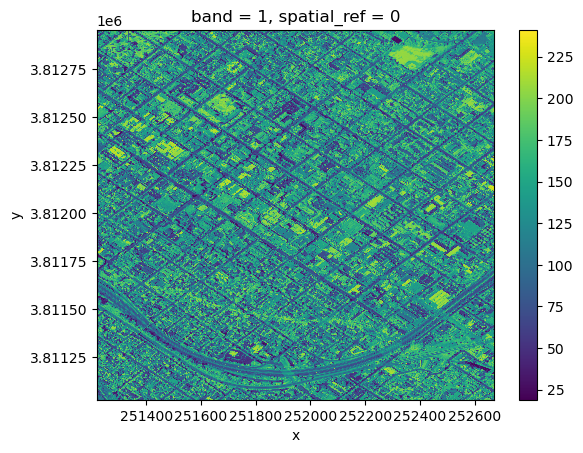

In [5]:
print('Sizes of dimnensions', dict(nir.sizes))

- `band` has length 1, so it makes the `xarray` 3-dimensional for no reason
- `squeeze` remnoves a dimension of length 1
- `drop=True` remove the coordinates for that dimension

In [6]:
# Original dimensions and coords
print(nir.dims, nir.coords, '\n')

# Remove length 1 dimension (band) and its coords
nir = nir.squeeze('band', drop=True)
print(nir.dims, nir.coords, '\n')

('band', 'y', 'x') Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 

('y', 'x') Coordinates:
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 



## `rio` accessor

In [7]:
# Examine raster attributes using rio accessor
print('Number of bands: ', nir.rio.count)
print('Height: ', nir.rio.height)
print('Width: ', nir.rio.width, '\n')

print('CRS: ', nir.rio.crs, '\n')

print('Spatial bounding box: ')
print(nir.rio.bounds())

Number of bands:  1
Height:  3208
Width:  2419 

CRS:  EPSG:26911 

Spatial bounding box: 
(251218.8, 3811027.2, 252670.19999999998, 3812952.0)


In [8]:
# Import RGB raster
fp = os.path.join('data', 'NAIP_SB', 'NAIP_SB_rgb.tif')
rgb = rioxr.open_rasterio(fp)
rgb

<xarray.DataArray (band: 3, y: 3208, x: 2419)> Size: 23MB
[23280456 values with dtype=uint8]
Coordinates:
  * band         (band) int64 24B 1 2 3
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

Check-in
Obtain this information:
- shape
- number of bands
- data type
- crs

In [9]:
# Examine raster attributes using rio accessor
print('Shape: ', rgb.shape)
print('Data type: ', rgb.dtype, '\n')
print('Number of bands: ', rgb.rio.count)
print('CRS: ', rgb.rio.crs)

Shape:  (3, 3208, 2419)
Data type:  uint8 

Number of bands:  3
CRS:  EPSG:26911


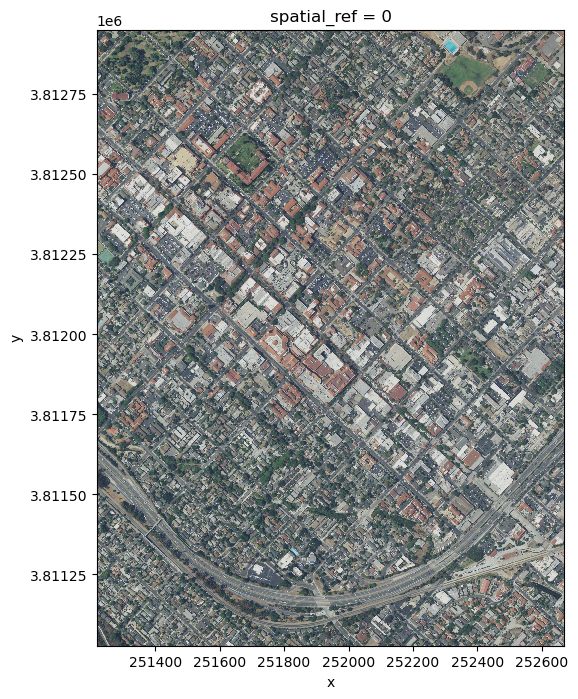

In [10]:
# Plot three bands as RGB image
rgb_aspect_ratio = rgb.rio.width / rgb.rio.height
rgb.plot.imshow(figsize=(8*rgb_aspect_ratio, 8)) # Number is in inches, multiply first by aspect ratio

## Clip raster

Our AOI is a few blocks around the NCEAS building, outlined in a GeoJSON file:

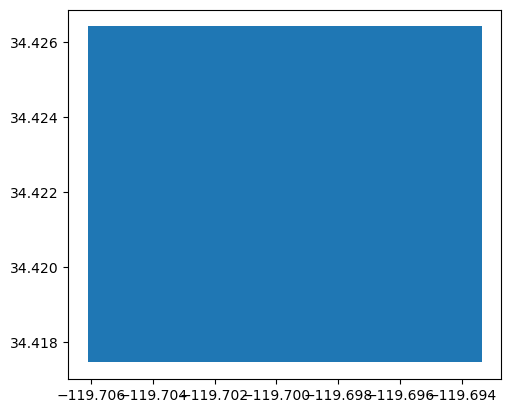

In [11]:
# Import area of interest as geopandas df
fp = os.path.join('data', 'SB_aoi.geojson')
aoi = gpd.read_file(fp)
aoi.plot();

In [12]:
# Examine the CRSs
print('aoi CRS:', aoi.crs)
print('nir CRS:', nir.rio.crs)
print('rgb CRS:', rgb.rio.crs)

aoi CRS: EPSG:4326
nir CRS: EPSG:26911
rgb CRS: EPSG:26911


In [13]:
# Reproject AOI to RGB CRS
aoi = aoi.to_crs(rgb.rio.crs)
assert aoi.crs == rgb.rio.crs

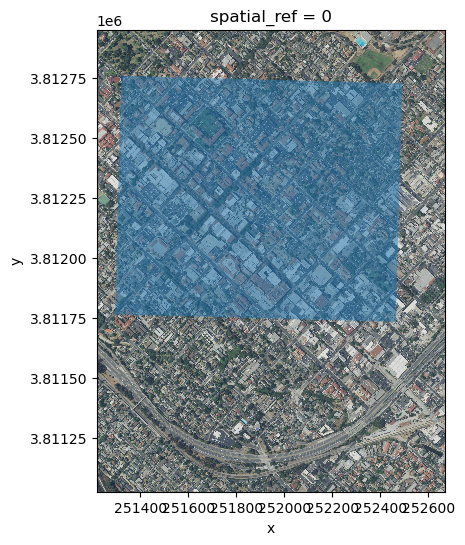

In [14]:
# Plot RGB raster with AOI overlay
fig, ax = plt.subplots(figsize = (6*rgb_aspect_ratio, 6))
rgb.plot.imshow(ax=ax)
aoi.plot(ax=ax, alpha=0.5)
plt.show()

In [15]:
aoi.total_bounds

array([ 251294.31339082, 3811734.95697039,  252490.65041356,
       3812760.09703315])

In [16]:
rgb_small = rgb.rio.clip_box(*aoi.total_bounds) # `*` unpacks info

In [17]:
nir_small = nir.rio.clip_box(*aoi.total_bounds)

Original shape (3208, 2419)
Clipped shape (1710, 1995)


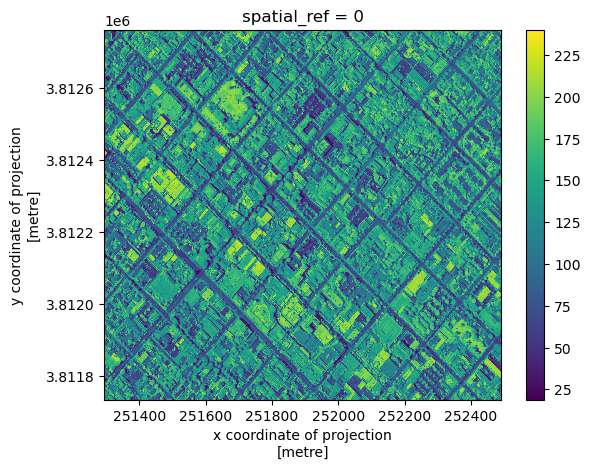

In [18]:
# Examine clipped data
print('Original shape', nir.shape)
print('Clipped shape', nir_small.shape)

nir_small.plot()

## Raster math

We will compute the **Normalized Difference Vegetation Index (NDVI)** over our AOI.

NDVI checks whether an area has live green vegetation

NDVI is always between -1 and 1: 
- values about 0.6 correspond to lush vegetation
- Close to zero or negative: water, roofs, pavement
- 0.1 and below: sand, rock, snow
- Generally above ~0.1 is vegetation

NDVI uses the NIR and red bands:
NDVI = (NIR - Red) / (NIR + Red)

In [19]:
# Select dimension by name and coordinate by label
red_small = rgb_small.sel(band=1)
red_small

<xarray.DataArray (y: 1710, x: 1995)> Size: 3MB
[3411450 values with dtype=uint8]
Coordinates:
    band         int64 8B 1
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [20]:
ndvi = (nir_small - red_small) / (nir_small + red_small)
ndvi

<xarray.DataArray (y: 1710, x: 1995)> Size: 27MB
array([[           inf, 3.37500000e+00, 9.25000000e+00, ...,
        5.85000000e+01, 1.18811881e+00, 2.46913580e-02],
       [2.93650794e-01,            inf, 2.88888889e+00, ...,
        3.50000000e+00, 2.35000000e+02, 6.54205607e-02],
       [3.20158103e-01, 3.23076923e-01, 3.49112426e-01, ...,
        4.32203390e+00, 1.66666667e-01, 5.28571429e+00],
       ...,
       [3.96039604e-02, 1.06779661e+00, 9.76470588e-01, ...,
        3.63492063e+00, 4.22222222e+00, 8.70370370e+00],
       [1.06521739e+01, 9.92156863e-01, 8.06451613e-03, ...,
        4.10714286e+00, 3.69696970e+00, 2.14018692e+00],
       [1.10869565e+01, 6.83783784e+00, 0.00000000e+00, ...,
        3.93750000e+00, 1.95934959e+00, 1.51282051e+00]])
Coordinates:
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
    band         int64 8B 1

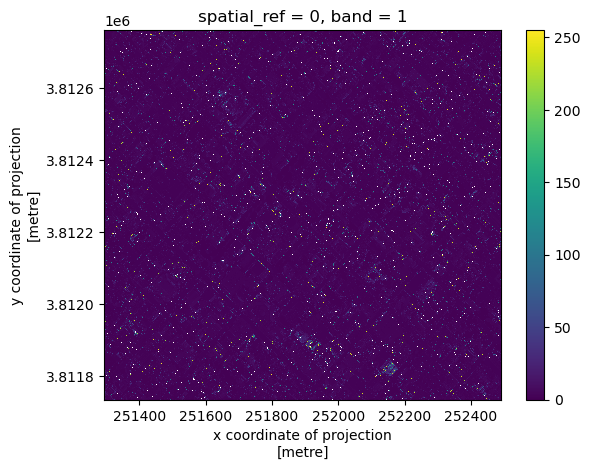

In [21]:
ndvi.plot() # Datatype issue

## Data type issue

In [23]:
nir_small.dtype

dtype('uint8')

We can see the data type for this raster is `unit8` = 8-bit unsigned integer = only holds integers from 0-255.
Calculations wrap around (modulo 256)

In [24]:
150 +150

300

In [27]:
np.uint8(150) + np.uint8(150)

/tmp/ipykernel_194896/1890984988.py:1: RuntimeWarning: overflow encountered in scalar add
  np.uint8(150) + np.uint8(150)


44

**Avoid silent failures!! ALWAYS verify your results**

We will fix this by updating the datatype

In [31]:
# Update data type to int16 to perform NDVI calculations
red16 = red_small.astype('int16')
nir16 = nir_small.astype('int16')
print('RED: original dtype:', red_small.dtype, '... converted dtype:', red16.dtype)
print('NIR: original dtype:', nir_small.dtype, '... converted dtype:', nir16.dtype)

RED: original dtype: uint8 ... converted dtype: int16
NIR: original dtype: uint8 ... converted dtype: int16


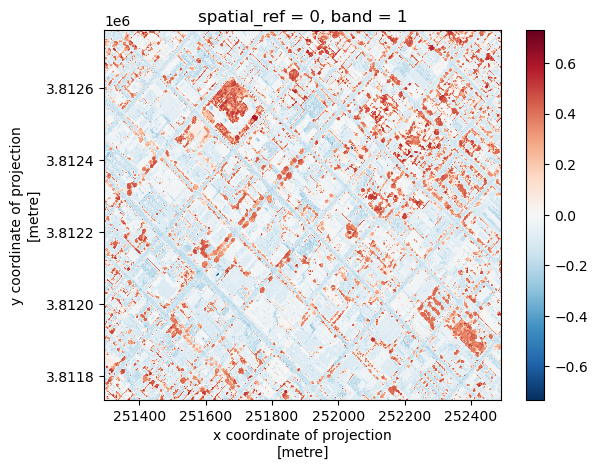

In [32]:
# Calculate NDVI
ndvi = (nir16 - red16) / (nir16 + red16)
ndvi.plot()

RED: original dtype: uint8 .... converted dtype: int16
NIR: original dtype: uint8 .... converted dtype: int16


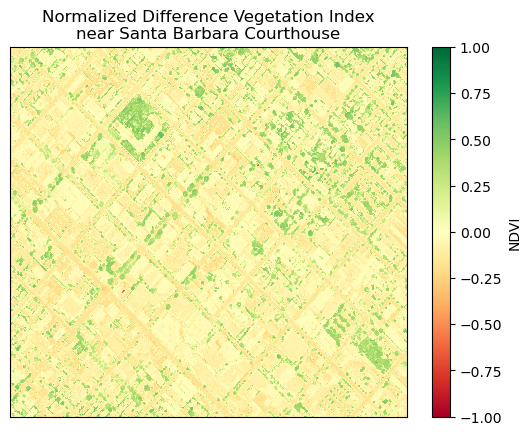

In [33]:
# Update data type to int16 to perform NDVI calculation
red16 = red_small.astype('int16')
nir16 = nir_small.astype('int16')

print('RED: original dtype:', rgb_small.dtype, '.... converted dtype:', red16.dtype)
print('NIR: original dtype:', nir.dtype, '.... converted dtype:', nir16.dtype)

# Calculate NDVI
ndvi = (nir16 - red16)/(nir16+red16)

# Plot
fig, ax = plt.subplots()  # Create figure and axes
ndvi.plot(
    ax=ax,
    cmap="RdYlGn",  # Colormap for NDVI
    vmin=-1,  # Minimum value
    vmax=1,   # Maximum value
    cbar_kwargs={"label": "NDVI"}  # Label for color bar
)
ax.set_title("Normalized Difference Vegetation Index\nnear Santa Barbara Courthouse")  # Add title

# Remove axes ticks
ax.set_xticks([])  
ax.set_yticks([])  

# Remove axes labels
ax.set_xlabel("")  
ax.set_ylabel("")  

plt.show()